# 15. The DMRG starting state as a circuit

**Goal.** Turn the matrix product state that DMRG returns into gates a quantum computer can run, check the prepared state exactly, and find out what it costs next to the phase estimation it feeds.

Notebook 14 showed that phase estimation succeeds with probability $\gamma^2 = |\langle\phi|E_0\rangle|^2$, and that a small DMRG state $|\phi\rangle$ keeps $\gamma^2$ of order one where a product state is hopeless. But the quantum computer has to *make* $|\phi\rangle$ before every run. This notebook builds that circuit two ways: exactly, with one gate per site on a few extra qubits, and approximately, with layers of two-qubit gates.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pennylane as qml
import pennylane.estimator as qre

from dmrg_from_scratch import build_mpo, dmrg_ladder, ground_state, j1j2_cylinder, tfim_cylinder, to_dense
from dmrg_from_scratch.circuits import disentangling_layers, mps_circuit, site_unitaries, to_pennylane_mps
from dmrg_from_scratch.resources import qpe_cost

## 1. The recipe in one call

Take the 4 x 4 J1-J2 cylinder of notebooks 11-14 ($J_2/J_1 = 0.5$, 16 spins), run DMRG at a few small bond dimensions, and keep the $\chi = 8$ state. `mps_circuit` places its gates in a PennyLane circuit. The circuit needs $k = \log_2\chi = 3$ extra qubits, the *work wires*, next to the 16 spins.

In [2]:
H = j1j2_cylinder(4)
E0, psi0 = ground_state(H)
ladder = dmrg_ladder(build_mpo(H), [1, 2, 4, 8, 16], n_sweeps=3)
mps = ladder[3]["mps"]  # chi = 8
n, k = H.n, 3

@qml.qnode(qml.device("default.qubit", wires=k + n))
def prepare_phi():
    mps_circuit(mps, wires=range(k, k + n), work_wires=range(k))
    return qml.state()

state = prepare_phi()
phi = to_dense(mps) / np.linalg.norm(to_dense(mps))
print("overlap of the circuit's state with the MPS:   ", abs(np.vdot(phi, state[: 2**n])))
print("weight left on the work wires:                 ", np.linalg.norm(state[2**n :]))
print("success probability gamma^2 = |<E0|circuit>|^2:", abs(np.vdot(psi0, state[: 2**n])) ** 2)

overlap of the circuit's state with the MPS:    0.9999999999999959
weight left on the work wires:                  0.0
success probability gamma^2 = |<E0|circuit>|^2: 0.921231687104436


The circuit makes the DMRG state to machine precision, hands the work wires back in $|000\rangle$, and the state has $\gamma^2 \approx 0.92$ with the exact ground state: phase estimation started from it would succeed 92% of the time.

## 2. What each gate does

The circuit is *sequential generation* [Schön, Solano, Verstraete, Cirac and Wolf, [arXiv:quant-ph/0501096](https://arxiv.org/abs/quant-ph/0501096)]. The work wires hold the bond index $a$ of the MPS. Site by site, one unitary acts on the work wires and on that site's qubit, which is still $|0\rangle$:

$$
U_i\,|a\rangle|0\rangle = \sum_{s,b} B_i[a, s, b]\;|b\rangle|s\rangle .
$$

It writes the spin $s$ onto the site and the next bond index $b$ back onto the work wires. Chaining the $U_i$ multiplies the tensors $B_0 B_1 \cdots$ exactly as the MPS does. Two facts make this a circuit:

* the columns $|a\rangle|0\rangle \mapsto \sum B_i[a,s,b]\,|b\rangle|s\rangle$ are orthonormal exactly when $\sum_{s,b} B_i[a,s,b]\,\overline{B_i[a',s,b]} = \delta_{aa'}$, which is the right-canonical form DMRG already returns; the other columns of $U_i$ can be any orthonormal completion;
* the first bond and the last bond have dimension 1, so the work wires start in $|0\rangle$ and end in $|0\rangle$, unentangled.

The smallest example is the GHZ state $(|000\rangle + |111\rangle)/\sqrt2$, an MPS with $\chi = 2$ (one work wire). Here are its three gates, each on (work wire, site), in the basis $|00\rangle, |01\rangle, |10\rangle, |11\rangle$:

In [3]:
r = 1 / np.sqrt(2)
B0 = np.array([[[r, 0], [0, r]]])  # B0[0, s, b] = delta_sb / sqrt 2
B1 = np.zeros((2, 2, 2)); B1[0, 0, 0] = B1[1, 1, 1] = 1  # B1[a, s, b] = delta_as delta_sb
B2 = np.zeros((2, 2, 1)); B2[0, 0, 0] = B2[1, 1, 0] = 1  # B2[a, s] = delta_as
ghz_gates, _ = site_unitaries([B0, B1, B2])
np.set_printoptions(precision=2, suppress=True)
for i, U in enumerate(ghz_gates):
    print(f"U_{i} =\n{U + 0.0}")  # + 0.0 turns -0 into 0

U_0 =
[[ 0.71  0.    0.   -0.71]
 [ 0.    1.    0.    0.  ]
 [ 0.    0.    1.    0.  ]
 [ 0.71  0.    0.    0.71]]
U_1 =
[[ 1.  0.  0.  0.]
 [ 0.  0.  0. -1.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]]
U_2 =
[[1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]]


Read the columns for inputs $|a\rangle|0\rangle$ (the first and third). $U_0$ sends $|00\rangle \to (|00\rangle + |11\rangle)/\sqrt2$: a Bell pair between the work wire and site 0. $U_1$ sends $|a\rangle|0\rangle \to |a\rangle|a\rangle$: a CNOT from the work wire onto site 1. $U_2$ sends $|a\rangle|0\rangle \to |0\rangle|a\rangle$: it moves the work wire's bit onto site 2 and resets the work wire. The other columns are the completion.

PennyLane ships the same construction as `qml.MPSPrep`, following Eq. (23) of Fomichev et al. [arXiv:2310.18410](https://arxiv.org/abs/2310.18410). It wants the end tensors as matrices and every bond a power of two; `to_pennylane_mps` converts. Same state:

In [4]:
@qml.qnode(qml.device("default.qubit", wires=k + n))
def prepare_phi_pennylane():
    qml.MPSPrep(to_pennylane_mps(mps), wires=range(k, k + n), work_wires=range(k))
    return qml.state()

print("overlap with our circuit:", abs(np.vdot(state, prepare_phi_pennylane())))

overlap with our circuit: 0.9999999999999956


## 3. What the circuit costs

Each $U_i$ is a generic unitary on $k + 1 = \log_2\chi + 1$ qubits. A generic unitary on $m$ qubits needs a number of CNOTs that grows like $4^m$, so the circuit costs about $n\chi^2$ gates. `pennylane.estimator` counts them from $n$ and $\chi$ alone; the rotations become T gates by gate synthesis, the unit notebook 13 counts in. For the 16 spins:

In [5]:
chis = [1, 2, 4, 8, 16]
prep = {}
for chi in chis:
    res = qre.estimate(qre.MPSPrep(num_mps_matrices=n, max_bond_dim=chi))
    gates = {str(g): c for g, c in res.gate_counts.items()}
    prep[chi] = gates["T"] + gates.get("Toffoli", 0)
    print(f"chi = {chi:2d}   CNOT = {gates.get('CNOT', 0):6d}   T = {gates['T']:8d}   qubits = {res.total_wires}")

q = qpe_cost(H, eps=0.01)
qpe = q["toffoli"] + q["T"]
print(f"\none phase estimation to eps = 0.01: {q['toffoli']:.2e} Toffoli + {q['T']:.2e} T on {q['logical_qubits']} qubits")

chi =  1   CNOT =      0   T =     2112   qubits = 16
chi =  2   CNOT =     48   T =    10560   qubits = 17
chi =  4   CNOT =    342   T =    45672   qubits = 18
chi =  8   CNOT =   1494   T =   172392   qubits = 19
chi = 16   CNOT =   5574   T =   605352   qubits = 20

one phase estimation to eps = 0.01: 3.41e+06 Toffoli + 8.40e+05 T on 124 qubits


Preparing the state is not free. At $\chi = 16$ it already costs about a seventh of a whole phase estimation in non-Clifford gates. And the state has to be made again for every repetition. So the expected cost is

$$
\text{cost}(\chi_0) = \frac{\text{prep}(\chi_0) + \text{QPE}}{\gamma^2(\chi_0)} ,
$$

and a larger $\chi_0$ buys a larger $\gamma^2$ at a growing price. On the 4 x 4 cylinder the exact $\gamma^2$ is known for each rung of the ladder above:

chi_0 =  1   gamma^2 = 0.007   expected non-Clifford gates = 5.74e+08   (135.0 x one QPE)
chi_0 =  2   gamma^2 = 0.416   expected non-Clifford gates = 1.03e+07   (  2.4 x one QPE)
chi_0 =  4   gamma^2 = 0.845   expected non-Clifford gates = 5.09e+06   (  1.2 x one QPE)
chi_0 =  8   gamma^2 = 0.921   expected non-Clifford gates = 4.80e+06   (  1.1 x one QPE)
chi_0 = 16   gamma^2 = 0.997   expected non-Clifford gates = 4.87e+06   (  1.1 x one QPE)


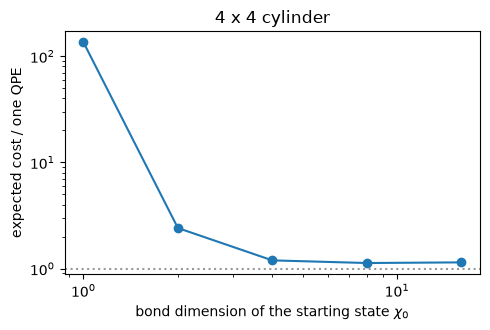

In [6]:
gamma2 = np.array([abs(to_dense(r["mps"]) @ psi0) ** 2 for r in ladder])
total = np.array([(prep[chi] + qpe) for chi in chis]) / gamma2
for chi, g2, t in zip(chis, gamma2, total):
    print(f"chi_0 = {chi:2d}   gamma^2 = {g2:.3f}   expected non-Clifford gates = {t:.2e}   ({t / qpe:5.1f} x one QPE)")

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.loglog(chis, total / qpe, "o-")
ax.axhline(1, color="0.6", ls=":")
ax.set(xlabel=r"bond dimension of the starting state $\chi_0$", ylabel="expected cost / one QPE", title="4 x 4 cylinder")
fig.tight_layout()

The product state ($\chi_0 = 1$) is cheap to make but needs about 135 repetitions. From $\chi_0 = 4$ on, the total is within 20% of a single phase estimation, and the curve is flat: $\chi_0 = 8$ is best, at 1.1 times one phase estimation, and $\chi_0 = 16$ is no better, because the overlap it adds is paid for in preparation. A modest bond dimension is all the starting state needs. Fomichev et al. [arXiv:2310.18410](https://arxiv.org/abs/2310.18410) build this trade-off into an end-to-end recipe for molecules, scoring candidate states by their energy distribution.

## 4. Shallower circuits: layers of two-qubit gates

The exact circuit uses gates on $\log_2\chi + 1$ qubits, which a real device must compile into many two-qubit gates. For $\chi = 2$ the work wire can be the *next site's* qubit, so a $\chi = 2$ MPS is a staircase of $n - 1$ two-qubit gates on neighbouring qubits. Ran [arXiv:1908.07958](https://arxiv.org/abs/1908.07958) stacks such staircases:

1. truncate the target state to $\chi = 2$ and build its staircase $U_1$;
2. undo it, $|\psi\rangle \to U_1^\dagger|\psi\rangle$, which is closer to $|0\cdots0\rangle$;
3. repeat on what is left. After $K$ layers, $U_1 \cdots U_K|0\cdots0\rangle$ approximates $|\psi\rangle$ with fidelity $|\langle 0\cdots0|U_K^\dagger\cdots U_1^\dagger|\psi\rangle|$.

Each two-qubit gate needs three CNOTs [Vidal and Dawson, [arXiv:quant-ph/0307177](https://arxiv.org/abs/quant-ph/0307177)]. We apply it to two exact ground states: the critical TFIM chain ($h = 1$, 12 spins) and the 4 x 4 J1-J2 cylinder.

TFIM, fidelity^2 after 1 and 8 layers: 0.9948 0.9982
J1-J2, fidelity^2 after 1 and 8 layers: 0.4259 0.7634


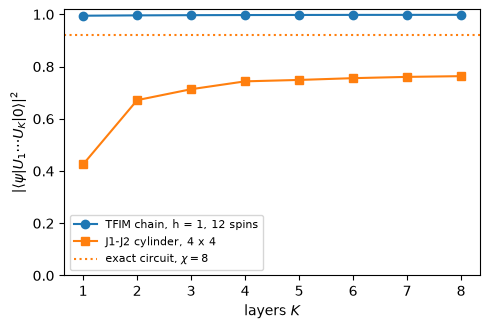

In [7]:
_, psi_tfim = ground_state(tfim_cylinder(1, Lx=12, h=1.0))  # a cylinder of width 1 is the open chain
_, F_tfim = disentangling_layers(psi_tfim, 8)
_, F_j1j2 = disentangling_layers(psi0, 8)

K = np.arange(1, 9)
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(K, np.array(F_tfim) ** 2, "o-", label="TFIM chain, h = 1, 12 spins")
ax.plot(K, np.array(F_j1j2) ** 2, "s-", label="J1-J2 cylinder, 4 x 4")
ax.axhline(gamma2[3], color="C1", ls=":", label=r"exact circuit, $\chi = 8$")
ax.set(xlabel="layers $K$", ylabel=r"$|\langle\psi|U_1\cdots U_K|0\rangle|^2$", ylim=(0, 1.02))
ax.legend(fontsize=8)
fig.tight_layout()
print("TFIM, fidelity^2 after 1 and 8 layers:", round(F_tfim[0] ** 2, 4), round(F_tfim[-1] ** 2, 4))
print("J1-J2, fidelity^2 after 1 and 8 layers:", round(F_j1j2[0] ** 2, 4), round(F_j1j2[-1] ** 2, 4))

On the chain one layer is already enough: 11 two-qubit gates (33 CNOTs) give $|\langle\psi|\phi\rangle|^2 = 0.995$. The cylinder is harder. The MPS walks through it column by column, so its entanglement is spread over long distances in the chain order, and each layer of nearest-neighbour gates removes less. The layers stall near 0.76, below the exact $\chi = 8$ circuit (dotted). Stacking greedily is only a starting point. Rudolph et al. [arXiv:2209.00595](https://arxiv.org/abs/2209.00595) optimize the gates after building them and get much higher fidelity at the same depth.

Per layer the cost is $15 \times 3 = 45$ CNOTs here, and $15 \times 660$ T gates for the rotations:

In [8]:
two_qubit = {str(g): c for g, c in qre.estimate(qre.QubitUnitary(num_wires=2)).gate_counts.items()}
per_layer = (n - 1) * two_qubit["T"]
print(f"one layer: {n - 1} gates, {3 * (n - 1)} CNOTs, {per_layer:.2e} T")
print(f"8 layers: {8 * per_layer:.2e} T, against {prep[8]:.2e} T for the exact chi = 8 circuit")

one layer: 15 gates, 45 CNOTs, 9.90e+03 T
8 layers: 7.92e+04 T, against 1.72e+05 T for the exact chi = 8 circuit


Eight layers cost about half as many T gates as the exact $\chi = 8$ circuit, and they use no work wires, but the fidelity is lower: on this cylinder the exact sequential circuit is the better buy. On chains, where a layer or two suffices, the layered circuit wins easily.

## What this means

* The DMRG state reaches the quantum computer as a circuit of $n$ gates on $\log_2\chi + 1$ qubits each, read straight off the right-canonical tensors. The cost grows like $n\chi^2$.
* Phase estimation repeats about $1/\gamma^2$ times and re-prepares the state each time. The best starting state balances preparation cost against overlap, and on the 4 x 4 cylinder any $\chi_0$ from 4 to 16 comes within 20% of a single phase estimation, while the product state costs 135 of them.
* Shallow layered circuits are cheap and work very well in one dimension. On cylinders they need optimization to compete.

## Exercises

1. Build the circuit for the TFIM chain at $h = 0.5$ with $\chi = 2$ using `site_unitaries`, and with `staircase` from `dmrg_from_scratch.circuits`. Both make the same state. Which uses fewer qubits, and why does the staircase need no work wire?
2. Fit the T count of `qre.MPSPrep` against $\chi$ for $\chi = 2, \dots, 64$. Is it $\propto \chi^2$? Explain the slope from the size of each $U_i$.
3. Repeat Section 3 on the 4 x 4 cylinder with `J2=0` (the unfrustrated model). Does the best $\chi_0$ change?
4. For the 6 x 6 and 8 x 8 cylinders the exact ground state is unknown. Use the overlaps with the best MPS stored in `results/dmrg_ladders.json` (see `overlap_of` in notebook 14) and `qre.MPSPrep` to estimate the best $\chi_0$ there. Does it grow with the system size?
5. Improve Ran's layers: after each new staircase, re-optimize its gates to maximize the fidelity (for example by sweeping over the gates and replacing each one by the polar decomposition of its environment). How much does the plateau on the cylinder rise?